### **Exploring a real protein in UniProt**

Human glycophorin A, P02724.

Imports for sequence and structure visualisation

- **Primary structure:** the amino acid sequence, stored below as `canonical_sequence`.
- **Secondary structure:** local shapes such as alpha helices and beta sheets. A transmembrane helix is an alpha helix that crosses a membrane.
- **Tertiary structure:** the three-dimensional fold of one protein chain.

For our first plot, we will use Matplotlib to mark annotated regions along the sequence, with residue positions starting at 1.

For a 3D view, `py3Dmol` displays atomic coordinates from a structure file such as PDB or mmCIF. It does not predict a fold from the sequence. We will need to obtain an experimental structure or a predicted model, check which part of the sequence it covers, and record its source.

The 3D viewer is optional for this first exercise. If it is missing, run `%pip install "py3Dmol>=2.4,<3"` in a separate cell, then rerun the imports. [Viewer documentation](https://pypi.org/project/py3Dmol/).

In [7]:
import requests  # Download UniProt records or structure files when needed.

# Optional: interactive 3D display of an existing protein structure.
try:
    import py3Dmol
except ModuleNotFoundError as exc:
    if exc.name != "py3Dmol":
        raise
    py3Dmol = None
    print('3D viewer unavailable. For 3D, run %pip install "py3Dmol>=2.4,<3" in a separate cell, then rerun this cell.')

https://www.uniprot.org/uniprotkb/P02724/entry#sequences

P02724-1
This isoform has been chosen as the canonical sequence. All positional information in this entry refers to it. This is also the sequence that appears in the downloadable versions of the entry.

This is the sequence I get when I copy from the website:
MYGKIIFVLLLSEIVSISALSTTEVAMHTSTSSSVTKSYISSQTNDTHKRDTYAATPRAHEVSEISVRTVYPPEEETGERVQLAHHFSEPEITLIIFGVMAGVIGTILLISYGIRRLIKKSPSDVKPLPSPDTDVPLSSVEIENPETSDQ

Length: 150

Mass (Da): 16,430

In [8]:
canonical_sequence = "MYGKIIFVLLLSEIVSISALSTTEVAMHTSTSSSVTKSYISSQTNDTHKRDTYAATPRAHEVSEISVRTVYPPEEETGERVQLAHHFSEPEITLIIFGVMAGVIGTILLISYGIRRLIKKSPSDVKPLPSPDTDVPLSSVEIENPETSDQ"
assert len(canonical_sequence) == 150 # check the length is consistent with that is on the website

In [9]:
distinct_amino_acids = set()

for amino_acid in canonical_sequence:
    if amino_acid not in distinct_amino_acids:
        distinct_amino_acids.add(amino_acid)

print(f"The canonical sequnece of PO2724 (PO2724-1) has {len(distinct_amino_acids)} different amino acids.")

The canonical sequnece of PO2724 (PO2724-1) has 18 different amino acids.


UniProt annotates residues 92–114 as a transmembrane helix (that stretch of the chain forms an alpha helix). The subcellular-location annotations have experimental support, as shown in the screenshot. I have not yet established the evidence for the exact region boundaries.

It's membrane-spanning segment starts exactly at residue 92 and ends at 114 (the screenshot does not establish these boundaries however).

The amino acid sequence of the region: **ITLIIFGVMAGVIGTILLISYGI**

In [10]:
canonical_sequence[91:114]

'ITLIIFGVMAGVIGTILLISYGI'

![Alt Text](screenshot.png)

### **Exploring Model Features**

In [11]:
import os
from pathlib import Path

# Tell InterPLM where to keep its project data.
# Set this before importing its inference functions.
os.environ["INTERPLM_DATA"] = str(Path("data/interplm").resolve())

import numpy as np
import matplotlib.pyplot as plt
import torch

from interplm.embedders import ESM
from interplm.sae.inference import load_sae_from_hf

/opt/anaconda3/envs/interpreting-plms/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Obtain ESM-2's representations of the sequence

In [ ]:
# start with the small, 8-million-parameter model and layer 4 - this layer is an exploratory starting choice
layer = 4

esm_model = ESM(
    model_name="facebook/esm2_t6_8M_UR50D", # publisher / model name (facebook is the publisher’s organisation name on HF)
    device="cpu",
)

# runs the protein sequence through ESM-2 and returns a numerical representation of each residue
# 1. converts the amino acid letters into tokens
# 2. passes the sequence through the pretrained model
# 3. extracts the representation of each residue from layer 4
# 4. removes the special start/end tokens and returns a NumPy array
embeddings = esm_model.embed_single_sequence(
    canonical_sequence,
    layer=layer,
)

print(type(embeddings))
# 150 rows - one per resiude
# 320 columns - the numbers forming that residue's representation (its embedding)
print(embeddings.shape)

<class 'numpy.ndarray'>
(150, 320)


In [18]:
embeddings[91]  # 320 numbers representing residue 92

array([-9.3358642e-01, -8.0633408e-01,  5.1583183e-01, -9.9388987e-01,
       -1.9776751e+00,  4.7068715e-02,  2.4175103e+00,  8.6691421e-01,
        9.0810591e-01, -3.8580641e-01,  4.8921299e-01, -2.1565115e-01,
        3.1727481e-01,  1.1866407e+00,  3.7385786e-01, -2.8003949e-01,
        1.0707070e+00, -1.0462997e+00,  1.4252861e+00, -1.5004587e-01,
       -2.0068902e-01,  5.3337020e-01,  1.0667768e+00, -9.9115729e-01,
        3.2685205e-01,  1.5829726e+00, -1.5051550e+00, -3.4519398e-01,
        1.7737707e+00, -5.0717974e-01, -4.4982725e-01,  1.2897170e-01,
       -4.2492944e-01,  3.4333855e-02, -2.3126793e-01,  2.4619406e-01,
        2.0066029e-01,  1.0178955e+00,  4.3009603e-01,  4.7853261e-01,
        1.8256438e+00,  5.8453554e-01, -6.1315548e-01, -7.1373338e-01,
        1.7393016e+00, -3.7374294e-01,  5.8695376e-01, -6.0531664e-01,
        1.9350486e+00, -1.5226839e+00,  4.3831527e-01,  2.4088764e+00,
        1.4149704e+00, -1.5141047e+00, -1.6943910e+00,  1.1088859e+00,
      

In [20]:
# each embedding depends on the surrounding sequence
# so two identical amino acids at different positions can have different embeddings
# these are internal model representations

In [25]:
# code needs explanations and codes from this point downwards!!!

#### Convert representations into feature activations

In [21]:
# the autoencoder must match the ESM-2 model and layer used above
sae = load_sae_from_hf(
    plm_model="esm2-8m",
    plm_layer=layer,
)
sae = sae.to("cpu").eval()

with torch.inference_mode():
    activations = sae.encode_feat_subset(
        torch.as_tensor(embeddings, dtype=torch.float32),
        list(range(sae.dict_size)),
        normalize_features=True,
    ).cpu().numpy()

print(activations.shape)

Loading configs from /Users/ishanmitra/.cache/huggingface/hub/models--Elana--InterPLM-esm2-8m/snapshots/81d2429cd9dae7175f1dcd8b4c649a20cdc06c8c/layer_4/config.yaml
Loaded data type: <class 'interplm.train.configs.TrainingRunConfig'>
Data keys: Not a dict
(150, 10240)


One residue -> 320 embedding values -> 10,240 SAE feature activations

#### Plot one active feature alongside the annotation

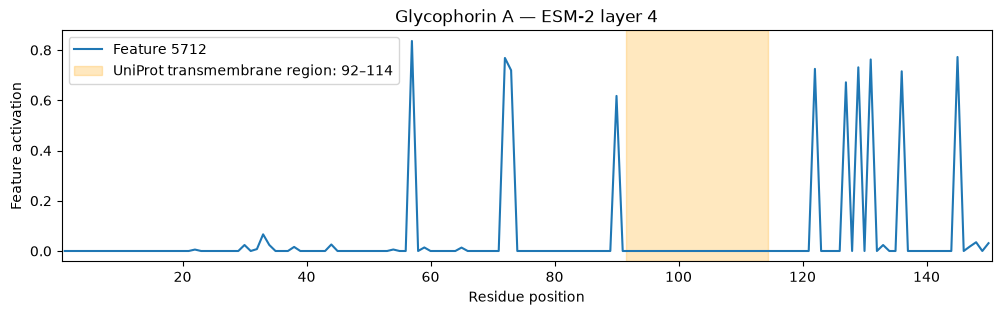

In [26]:
feature_id = int(activations.max(axis=0).argmax())
positions = np.arange(1, len(canonical_sequence) + 1)

fig, ax = plt.subplots(figsize=(12, 3))

ax.plot(positions, activations[:, feature_id],
        label=f"Feature {feature_id}")

ax.axvspan(91.5, 114.5, color="orange", alpha=0.25,
           label="UniProt transmembrane region: 92–114")

ax.set(
    xlabel="Residue position",
    ylabel="Feature activation",
    title=f"Glycophorin A — ESM-2 layer {layer}",
    xlim=(0.5, len(canonical_sequence) + 0.5),
)
ax.legend()
plt.show();